# B25 怎样让程序在有障碍的地图上找到路线？

任务：给配送小车寻找四方向可通行的最短路线。先定义合法移动，再用 Dijkstra 对照 A*，检查启发式为什么可用。

先修：B05、B13；元组、字典、生成器与 heapq。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 地图、状态与合法动作
状态是 (行,列) 元组，0 可走、1 障碍，每步成本 1。边界与障碍检查集中写在 neighbors 中；没有对角移动，曼哈顿距离才是对应的下界。

In [2]:
import json
import time
import numpy as np
started = time.perf_counter()
def finish(metrics):
    metrics["elapsed_seconds"] = round(time.perf_counter() - started, 3)
    (OUT_DIR / "metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
    print(json.dumps(metrics, ensure_ascii=False, indent=2))
def barplot(labels, values, title, filename="comparison.png"):
    fig, ax = plt.subplots()
    ax.bar(labels, values)
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(OUT_DIR / filename)
    plt.close(fig)

import heapq
from collections import deque
grid = np.array([[0, 0, 0, 1, 0, 0], [1, 1, 0, 1, 0, 1], [0, 0, 0, 0, 0, 0], [0, 1, 1, 1, 1, 0], [0, 0, 0, 0, 0, 0]], dtype=int)
start = (0, 0)
goal = (4, 5)

def neighbors(node, board):
    r, c = node
    for dr, dc in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
        nr, nc = (r + dr, c + dc)
        if 0 <= nr < board.shape[0] and 0 <= nc < board.shape[1] and (board[nr, nc] == 0):
            yield (nr, nc)

def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])
assert manhattan(start, goal) == 9
np.savetxt(DATA_DIR / 'map.csv', grid, fmt='%d', delimiter=',')

## 2. 优先队列与 g+h
g 保存当前已知的实际代价，h 是剩余代价下界。heapq 每次取最小 f；更短路径出现时更新父指针。旧队列项可能过时，要跳过，避免重复扩展污染统计。

In [3]:
def astar(board, source, target, use_heuristic=True):
    for p in [source, target]:
        if not (0 <= p[0] < board.shape[0] and 0 <= p[1] < board.shape[1]) or board[p] != 0:
            raise ValueError('起终点必须可通行')
    h = (lambda p: manhattan(p, target)) if use_heuristic else lambda p: 0
    queue = [(h(source), 0, source)]
    g = {source: 0}
    parent = {}
    expanded = 0
    while queue:
        _, distance, node = heapq.heappop(queue)
        if distance != g[node]:
            continue
        expanded += 1
        if node == target:
            path = [node]
            while node != source:
                node = parent[node]
                path.append(node)
            return (list(reversed(path)), expanded)
        for nxt in neighbors(node, board):
            tentative = distance + 1
            if tentative < g.get(nxt, float('inf')):
                g[nxt] = tentative
                parent[nxt] = node
                heapq.heappush(queue, (tentative + h(nxt), tentative, nxt))
    return ([], expanded)
path, expanded = astar(grid, start, goal)

## 3. 独立验证每一步与最短长度
检查路径从起点到终点、每步邻接、不穿障碍。再用不含启发式的 Dijkstra 对照最短长度；A* 能减少扩展是经验结果，不预设它在所有地图都更快。

In [4]:
def validate_path(board, path, source, target):
    return bool(path and path[0] == source and (path[-1] == target) and all((board[p] == 0 for p in path)) and all((b in set(neighbors(a, board)) for a, b in zip(path, path[1:]))))
reference, reference_expanded = astar(grid, start, goal, use_heuristic=False)
assert validate_path(grid, path, start, goal)
assert len(path) == len(reference)
blocked = np.array([[0, 1], [1, 0]])
assert astar(blocked, (0, 0), (1, 1))[0] == []

## 4. 输出路线和搜索工作量
图上展示坐标路径，JSON 保存可重放坐标。报告步数和扩展节点数，不把路径长度与运行时间混成一个指标。

In [5]:
fig, ax = plt.subplots()
ax.imshow(grid, cmap='Greys', vmin=0, vmax=1)
ax.plot([p[1] for p in path], [p[0] for p in path], '-o', color='tab:red')
ax.set_title('A* 最短可行路线')
ax.text(start[1], start[0], 'S', color='blue')
ax.text(goal[1], goal[0], 'G', color='blue')
fig.tight_layout()
fig.savefig(OUT_DIR / 'route.png')
plt.close(fig)
(OUT_DIR / 'path.json').write_text(json.dumps(path), encoding='utf-8')
finish({'steps': len(path) - 1, 'astar_expanded': expanded, 'dijkstra_expanded': reference_expanded, 'path_valid': True, 'unreachable_checked': True})

{
  "steps": 9,
  "astar_expanded": 10,
  "dijkstra_expanded": 18,
  "path_valid": true,
  "unreachable_checked": true,
  "elapsed_seconds": 0.104
}


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

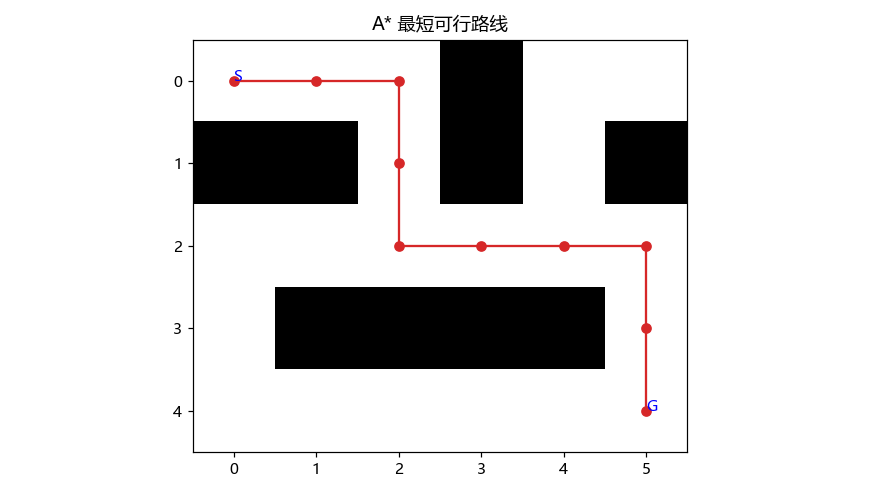

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
最短性依赖非负边代价与有效启发式；改成对角移动、带电量状态或动态路况后必须重审建模和启发式。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。